# Rock, Paper, Scissors — Live Game and Transfer Learning (Student Version)

This notebook uses the CNN trained and saved in the previous lecture (`rps_cnn_final.keras`) to referee a live Rock-Paper-Scissors game against the computer through the webcam. We then introduce transfer learning, build a second classifier on top of a pretrained MobileNetV2, and compare it against the from-scratch CNN on accuracy, training time, and model size.

Cells marked **`# TODO`** are for you to complete. Everything else is provided so you can focus on the concepts being tested in each section.

## 1. Requirements

The webcam section uses OpenCV to access the camera and must run on a local Jupyter kernel with a connected webcam — it will not work on a hosted notebook environment (Kaggle, Colab, Binder) since those do not expose a physical camera to the kernel. The transfer learning section has no such restriction and can run anywhere.

```
pip install opencv-python
```

## 2. Loading the trained model

Load the model you trained and saved in the previous session, then print its summary. The summary is how you check, before writing a single line of game logic, that the architecture and input shape are what you expect.

In [12]:
import cv2
import numpy as np
import random
import time
import tensorflow as tf

CLASS_NAMES = ["rock", "paper", "scissors"]  # must match the label order used in training
IMG_SIZE = 128

# TODO: load the model saved in the previous session ("rps_cnn_final.keras")
model = tf.keras.models.load_model("rps_cnn_final.keras")

print("Model loaded.")
# TODO: print a summary of the model's architecture
model.summary()

Model loaded.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,864,203 (49.07 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,576,136 (32.72 MB)

## 3. Game rules

Standard Rock-Paper-Scissors rules: rock beats scissors, scissors beats paper, paper beats rock. Same choice is a tie.

Implement `decide_winner` so it returns `"user"`, `"computer"`, or `"tie"`.

In [13]:
def decide_winner(user_choice, computer_choice):
    # TODO: implement the standard rock-paper-scissors rules
    # return "tie" if both choices are the same
    # return "user" if user_choice beats computer_choice
    # return "computer" otherwise
    beats = {
        "rock": "scissors",
        "scissors": "paper",
        "paper": "rock"
    }
    
    if user_choice == computer_choice:
        return "tie"
    elif beats[user_choice] == computer_choice:
        return "user"
    else:
        return "computer"

# sanity check
assert decide_winner("rock", "scissors") == "user"
assert decide_winner("scissors", "rock") == "computer"
assert decide_winner("paper", "paper") == "tie"
print("Rules check passed.")


Rules check passed.


## 4. Predicting a hand gesture from a webcam frame

A captured BGR frame from OpenCV must go through the same preprocessing used during training before it can be fed to the model: convert to RGB, resize to the model's input size, and rescale to `[0, 1]`. That part is done for you below. What's missing is the actual inference step: running the model on the batch and reading off the predicted class.

Recall that `model.predict(...)` returns a probability for *every* class (an array of 3 numbers here, one per gesture, summing to ~1). `np.argmax` gives you the index of the largest value in that array — i.e. the class the model is most confident about.

In [14]:
def predict_gesture(frame, model):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE))
    normalized = resized / 255.0
    batch = np.expand_dims(normalized, axis=0)

    # TODO: run the model on `batch` to get the 3 class probabilities for this frame
    probs = model.predict(batch, verbose=0)[0]

    # TODO: find the index of the highest probability using np.argmax
    predicted_index = np.argmax(probs)

    return CLASS_NAMES[predicted_index], float(probs[predicted_index])


## 5. Live game loop

The webcam feed is shown with an on-screen region of interest (ROI) box. Pressing **SPACE** captures the frame inside the ROI, runs it through the model, generates a random computer move, and displays the result for a few seconds. Pressing **Q** exits.

The OpenCV window/drawing code is provided as-is — focus on the two `TODO`s inside the SPACE-key branch, which tie together the two functions you just wrote.

In [15]:
def play_rps_game(model, camera_index=0):
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        raise RuntimeError("Could not open webcam. Check camera_index and permissions.")

    roi_top, roi_left, roi_size = 100, 100, 300
    user_score, computer_score = 0, 0
    result_text, result_until = "", 0

    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frame = cv2.flip(frame, 1)

            cv2.rectangle(
                frame,
                (roi_left, roi_top),
                (roi_left + roi_size, roi_top + roi_size),
                (0, 255, 0),
                2,
            )
            cv2.putText(
                frame, "SPACE: play  |  Q: quit", (20, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2,
            )
            cv2.putText(
                frame, f"You: {user_score}  Computer: {computer_score}", (20, 60),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2,
            )

            if time.time() < result_until:
                cv2.putText(
                    frame, result_text, (20, 460),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2,
                )

            cv2.imshow("Rock Paper Scissors", frame)
            key = cv2.waitKey(1) & 0xFF

            if key == ord("q"):
                break

            if key == ord(" "):
                roi = frame[roi_top:roi_top + roi_size, roi_left:roi_left + roi_size]

                # TODO: call predict_gesture on `roi` with the loaded `model`
                user_choice, confidence = predict_gesture(roi, model)

                computer_choice = random.choice(CLASS_NAMES)

                # TODO: call decide_winner to get "user", "computer", or "tie"
                winner = decide_winner(user_choice, computer_choice)

                if winner == "user":
                    user_score += 1
                    outcome = "You win!"
                elif winner == "computer":
                    computer_score += 1
                    outcome = "Computer wins!"
                else:
                    outcome = "Tie!"

                result_text = (
                    f"You: {user_choice} ({confidence:.0%})  "
                    f"Computer: {computer_choice}  ->  {outcome}"
                )
                result_until = time.time() + 3
                print(result_text)
    finally:
        # Always release the camera and close the window, even if an error
        # interrupts the loop above — otherwise the webcam stays locked.
        cap.release()
        cv2.destroyAllWindows()

play_rps_game(model)


## 6. Transfer learning

The CNN from the previous session was trained from scratch: every filter had to be learned from 2,520 training images. **Transfer learning** instead starts from a network already trained on a much larger dataset — typically ImageNet, 1.4 million images across 1,000 classes — and reuses its learned convolutional filters as a general-purpose feature extractor.

Why this helps here:

- The early and middle layers of an ImageNet-trained network already detect edges, textures, colors, and shapes that are useful for almost any image task, including hand gestures.
- With a small dataset like ours, training a deep network from scratch risks overfitting. Reusing pretrained filters and only training a small classification head needs far fewer parameters to fit.
- Training is faster because most of the network's weights are frozen (not updated) during backpropagation.

We use **MobileNetV2** as the pretrained base. Before touching the code, it's worth understanding what that network actually is, since the rest of this section leans on it.

## 7. Loading the data again

Same dataset and preprocessing pipeline as the previous session, with one difference: MobileNetV2 expects inputs preprocessed with its own `preprocess_input` function rather than a plain `/255.0` rescale.

In [4]:
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

(train_ds_raw, test_ds_raw), ds_info = tfds.load(
    "rock_paper_scissors",
    split=["train", "test"],
    as_supervised=True,
    with_info=True,
)

class_names = ds_info.features["label"].names
num_classes = len(class_names)

BATCH_SIZE = 32
MOBILENET_IMG_SIZE = 128

# MobileNetV2's own preprocessing function: rescales pixels to the [-1, 1]
mobilenet_preprocess = tf.keras.applications.mobilenet_v2.preprocess_input

def preprocess_mobilenet(image, label):
    # TODO: resize `image` to (MOBILENET_IMG_SIZE, MOBILENET_IMG_SIZE)
    # using tf.image.resize
    image = tf.image.resize(image, [MOBILENET_IMG_SIZE, MOBILENET_IMG_SIZE])

    # TODO: apply mobilenet_preprocess to `image`
    image = mobilenet_preprocess(image)

    return image, label

train_ds = (
    train_ds_raw
    .map(preprocess_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds_raw
    .map(preprocess_mobilenet, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")


## 8. Building the transfer learning model

`include_top=False` drops MobileNetV2's original 1,000-class ImageNet classification head, keeping only the convolutional base. `weights="imagenet"` loads the pretrained filters. Setting `base_model.trainable = False` freezes them so training only updates the new head.

In [5]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(MOBILENET_IMG_SIZE, MOBILENET_IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
)
# TODO: freeze the base model so its pretrained weights are not updated during training
base_model.trainable = False


tl_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MOBILENET_IMG_SIZE, MOBILENET_IMG_SIZE, 3)),
    data_augmentation,
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    # TODO: add the final classification Dense layer
    tf.keras.layers.Dense(num_classes, activation="softmax"),
])

tl_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Count the total and trainable parameters and confirm how small a fraction is actually trainable — this is the direct payoff of freezing the base and using `GlobalAveragePooling2D` instead of `Flatten`.

In [6]:
total_params = tl_model.count_params()

# TODO: sum the trainable parameters only (tl_model.trainable_weights)
trainable_params = sum(np.prod(w.shape) for w in tl_model.trainable_weights)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,} ({trainable_params / total_params:.1%} of total)")


Total parameters: 2,261,827
Trainable parameters: 3,843 (0.2% of total)


## 9. Training

In [7]:
tl_model.compile(
    optimizer="adam",
    # TODO: use the same loss as the from-scratch CNN (integer labels, not one-hot)
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "rps_mobilenet_best.keras", monitor="val_loss", save_best_only=True
    ),
]

start_time = time.time()
tl_history = tl_model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=15,
    callbacks=callbacks,
)
tl_training_seconds = time.time() - start_time
print(f"Transfer learning training time: {tl_training_seconds:.1f} seconds")


Epoch 1/15


c:\Tamkeen\8-Deep_learning\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 175ms/step - accuracy: 0.8460 - loss: 0.3864 - val_accuracy: 0.9409 - val_loss: 0.2422
Epoch 2/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 176ms/step - accuracy: 0.9722 - loss: 0.0985 - val_accuracy: 0.9328 - val_loss: 0.2329
Epoch 3/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 193ms/step - accuracy: 0.9794 - loss: 0.0673 - val_accuracy: 0.9543 - val_loss: 0.1345
Epoch 4/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 163ms/step - accuracy: 0.9913 - loss: 0.0408 - val_accuracy: 0.9543 - val_loss: 0.1486
Epoch 5/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 193ms/step - accuracy: 0.9917 - loss: 0.0349 - val_accuracy: 0.9516 - val_loss: 0.1400
Epoch 6/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 138ms/step - accuracy: 0.9956 - loss: 0.0250 - val_accuracy: 0.9597 - val_loss: 0.1095
Epoch 7/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 178ms/step - accuracy: 0.9933 - loss: 0.0259 - val_accuracy: 0.9677 - val_loss: 0.0811
Epoch 8/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 177ms/step - accuracy: 0.9964 - loss: 0.0182 - val_accuracy: 0.959

## 10. Comparing accuracy and speed against the from-scratch CNN

`scratch_training_seconds` and `scratch_history` should be carried over from the previous session's notebook (re-run its training cell first, or record the values manually below) so both models are compared on the same run.

In [8]:
# TODO: evaluate tl_model on test_ds
tl_test_loss, tl_test_accuracy = tl_model.evaluate(test_ds, verbose=0)
print(f"Transfer learning test accuracy: {tl_test_accuracy:.4f}")
print(f"Transfer learning test loss: {tl_test_loss:.4f}")

scratch_test_accuracy = 0.9758
scratch_total_params = 4_288_067

comparison_rows = [
    ("Metric", "From-scratch CNN", "Transfer learning (MobileNetV2)"),
    ("Test accuracy", scratch_test_accuracy, round(tl_test_accuracy, 4)),
    ("Total parameters", scratch_total_params, total_params),
    ("Trainable parameters", scratch_total_params, trainable_params),
]

for row in comparison_rows:
    print(f"{row[0]:<22} {str(row[1]):<20} {row[2]}")


Transfer learning test accuracy: 0.9892
Transfer learning test loss: 0.0528
Metric                 From-scratch CNN     Transfer learning (MobileNetV2)
Test accuracy          0.9758               0.9892
Total parameters       4288067              2261827
Trainable parameters   4288067              3843


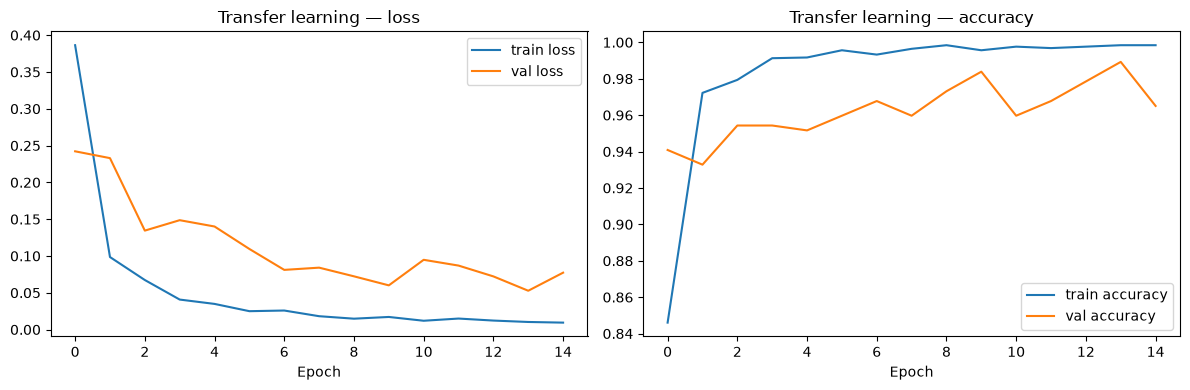

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(tl_history.history["loss"], label="train loss")
axes[0].plot(tl_history.history["val_loss"], label="val loss")
axes[0].set_title("Transfer learning — loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(tl_history.history["accuracy"], label="train accuracy")
axes[1].plot(tl_history.history["val_accuracy"], label="val accuracy")
axes[1].set_title("Transfer learning — accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


Typical outcome on this dataset: the transfer learning model reaches comparable or higher validation accuracy in fewer epochs, because it starts from ImageNet features instead of random weights, even though its total parameter count (MobileNetV2 base included) is larger than the from-scratch CNN — the key number for training cost is *trainable* parameters, which is much smaller here since the base is frozen.

## 11. Saving the transfer learning model

In [10]:
# TODO: save tl_model to "rps_mobilenet_final.keras"
tl_model.save("rps_mobilenet_final.keras")
print("Model saved to rps_mobilenet_final.keras")


Model saved to rps_mobilenet_final.keras


## 12. Playing against the transfer learning model

The same `play_rps_game` function works with either saved model — it only depends on the model's `predict` output matching `CLASS_NAMES`. Note the input size differs (128×128 for both models here, but `predict_gesture` would need updating if the two models used different `IMG_SIZE` values).

In [16]:
# TODO: load the model back from "rps_mobilenet_final.keras"
tl_loaded_model = tf.keras.models.load_model("rps_mobilenet_final.keras")
play_rps_game(tl_loaded_model)


You: scissors (78%)  Computer: paper  ->  You win!
You: paper (99%)  Computer: rock  ->  You win!
You: paper (97%)  Computer: rock  ->  You win!
You: paper (89%)  Computer: paper  ->  Tie!
You: rock (100%)  Computer: scissors  ->  You win!
You: scissors (100%)  Computer: rock  ->  Computer wins!
You: paper (75%)  Computer: rock  ->  You win!
